In [1]:
import sqlite3
import pandas as pd

DB_PATH = r"D:\projects\1\learning\data\kutubxona_v2.sqlite"
conn = sqlite3.connect(DB_PATH)

pd.read_sql("SELECT COUNT(*) AS loans FROM library_loan", conn)

,loans
0,3479


In [2]:
loans = pd.read_sql("SELECT * FROM library_loan", conn)

In [3]:
loans.head()

,id,loan_date,due_date,return_date,book_id,member_id
0,1,2024-12-06,2024-12-20,2024-12-25,25,268
1,2,2024-12-15,2024-12-29,2024-12-23,13,226
2,3,2024-12-16,2024-12-30,2024-12-28,10,226
3,4,2024-12-21,2025-01-04,2025-01-04,22,226
4,5,2024-12-24,2025-01-07,2025-02-03,20,156


In [4]:
loans.dtypes

id             int64
loan_date        str
due_date         str
return_date      str
book_id        int64
member_id      int64
dtype: object

In [5]:
loans.shape

(3479, 6)

In [6]:
pd.read_sql("SELECT COUNT(*) FROM library_member", conn)

,COUNT(*)
0,400


In [7]:
members=pd.read_sql("SELECT * FROM library_member", conn)

In [8]:
loans["loan_date"]=pd.to_datetime(loans["loan_date"])

In [9]:
loans.dtypes

id                      int64
loan_date      datetime64[us]
due_date                  str
return_date               str
book_id                 int64
member_id               int64
dtype: object

In [10]:
loans["loan_month"]=loans["loan_date"].dt.strftime('%Y-%m')

In [11]:
loans.head()

,id,loan_date,due_date,return_date,book_id,member_id,loan_month
0,1,2024-12-06,2024-12-20,2024-12-25,25,268,2024-12
1,2,2024-12-15,2024-12-29,2024-12-23,13,226,2024-12
2,3,2024-12-16,2024-12-30,2024-12-28,10,226,2024-12
3,4,2024-12-21,2025-01-04,2025-01-04,22,226,2024-12
4,5,2024-12-24,2025-01-07,2025-02-03,20,156,2024-12


In [12]:
loans.groupby("loan_month").size()

loan_month
2024-12     12
2025-01     33
2025-02     33
2025-03     47
2025-04     58
2025-05     98
2025-06     72
2025-07     80
2025-08     74
2025-09    132
2025-10    150
2025-11    154
2025-12    166
2026-01    189
2026-02    206
2026-03    238
2026-04    226
2026-05    241
2026-06    173
2026-07    201
2026-08    207
2026-09    269
2026-10    267
2026-11    153
dtype: int64

In [13]:
loans.book_id.value_counts().head(5)

book_id
1     228
7     186
13    183
22    165
29    152
Name: count, dtype: int64

In [14]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [15]:
monthly=loans.loc[loans["loan_month"]!='2026-11'].groupby("loan_month").size()

In [16]:
monthly

loan_month
2024-12     12
2025-01     33
2025-02     33
2025-03     47
2025-04     58
2025-05     98
2025-06     72
2025-07     80
2025-08     74
2025-09    132
2025-10    150
2025-11    154
2025-12    166
2026-01    189
2026-02    206
2026-03    238
2026-04    226
2026-05    241
2026-06    173
2026-07    201
2026-08    207
2026-09    269
2026-10    267
dtype: int64

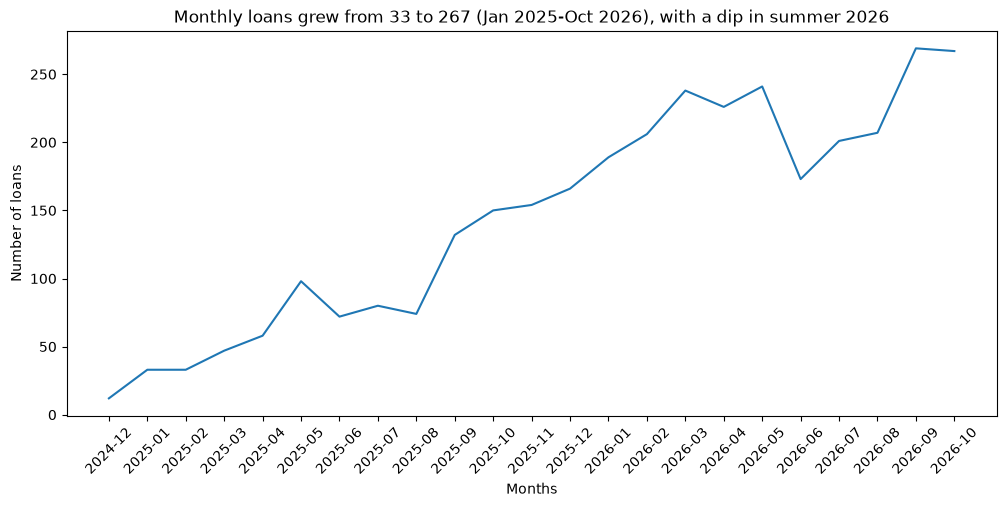

In [17]:
plt.figure(figsize=(12, 5))
plt.title("Monthly loans grew from 33 to 267 (Jan 2025-Oct 2026), with a dip in summer 2026")
sns.lineplot(data=monthly)
plt.xlabel("Months")
plt.xticks(rotation=45)
plt.ylabel("Number of loans")
plt.savefig("images/monthly_loans.png", dpi=150, bbox_inches="tight")

In [18]:
books=pd.read_sql("SELECT * FROM library_book", conn)

In [19]:
top10=loans.book_id.value_counts().head(10).reset_index()

In [20]:
top10_books=pd.merge(top10, books[["id", "title"]], left_on="book_id", right_on="id")

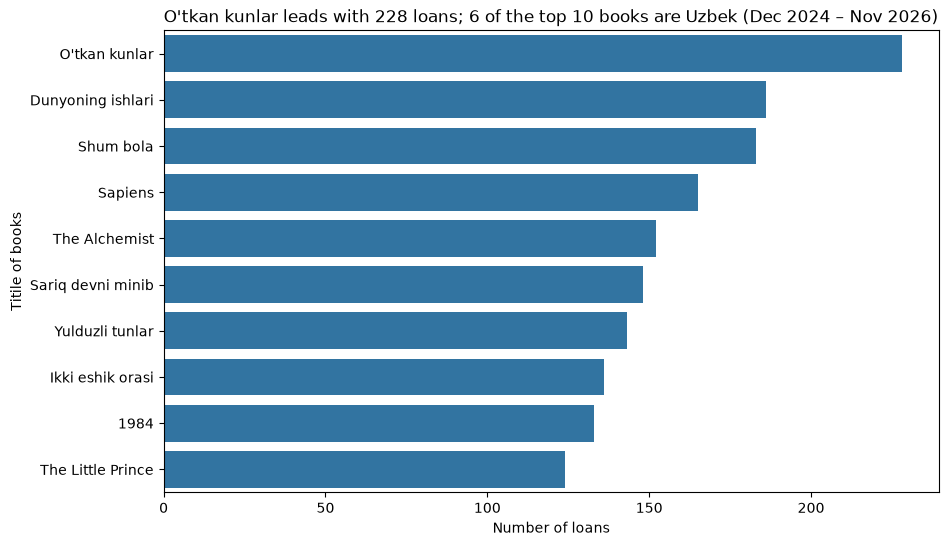

In [21]:
plt.figure(figsize=(10, 6))
plt.title("O'tkan kunlar leads with 228 loans; 6 of the top 10 books are Uzbek (Dec 2024 – Nov 2026)")
sns.barplot(x=top10_books["count"], y=top10_books["title"])
plt.xlabel("Number of loans")
plt.ylabel("Titile of books")
plt.savefig("images/top10_books.png", dpi=150, bbox_inches="tight")

In [22]:
cohort_sql= """
        WITH members AS(
SELECT id, STRFTIME('%Y-%m', joined_date)  AS cohort, 
		 CAST(STRFTIME('%Y', joined_date) AS integer)*12+CAST(STRFTIME('%m', joined_date) AS integer) AS join_idx
FROM library_member),
	activity AS(
SELECT DISTINCT member_id, CAST(STRFTIME('%Y', loan_date) AS integer)*12+CAST(STRFTIME('%m', loan_date) AS integer) AS loan_idx
FROM library_loan
WHERE loan_date<date('now', 'start of month')),
	cohort_size AS(
SELECT  cohort, COUNT(id) AS cohort_size
FROM members
GROUP BY cohort),
	retention AS(
SELECT  cohort, loan_idx-join_idx AS month_since_join, COUNT(id) AS active_members
FROM members
JOIN activity
ON members.id=activity.member_id
GROUP BY cohort, month_since_join)
SELECT c.cohort, cohort_size, 
		 MAX(CASE WHEN month_since_join=0 THEN ROUND(100.0*active_members/cohort_size, 1)  END) AS m0,
		 MAX(CASE WHEN month_since_join=1 THEN ROUND(100.0*active_members/cohort_size, 1) END)AS m1,
		 MAX(CASE WHEN month_since_join=2 THEN ROUND(100.0*active_members/cohort_size, 1) END)AS m2,
		 MAX(CASE WHEN month_since_join=3 THEN ROUND(100.0*active_members/cohort_size, 1) END)AS m3,
		 MAX(CASE WHEN month_since_join=6 THEN ROUND(100.0*active_members/cohort_size, 1) END)AS m6,
		 MAX(CASE WHEN month_since_join=12 THEN ROUND(100.0*active_members/cohort_size, 1) END)AS m12
FROM cohort_size AS c
JOIN retention AS r
ON c.cohort=r.cohort
GROUP BY c.cohort, c.cohort_size
ORDER BY c.cohort;
"""

In [23]:
cohort=pd.read_sql(cohort_sql, conn)
cohort

,cohort,cohort_size,m0,m1,m2,m3,m6,m12
0,2024-11,1,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-12,7,71.4,71.4,42.9,85.7,42.9,42.9
2,2025-01,14,64.3,50.0,42.9,50.0,21.4,7.1
3,2025-02,7,71.4,71.4,57.1,71.4,28.6,28.6
4,2025-03,9,66.7,55.6,55.6,11.1,66.7,22.2
5,2025-04,11,81.8,81.8,45.5,45.5,45.5,27.3
6,2025-05,18,72.2,66.7,55.6,38.9,50.0,33.3
7,2025-06,14,57.1,71.4,35.7,42.9,42.9,21.4
8,2025-07,11,45.5,63.6,54.5,27.3,27.3,27.3
9,2025-08,15,46.7,66.7,60.0,60.0,53.3,26.7


In [24]:
cohort=cohort.set_index("cohort")
cohort=cohort.drop(columns=["cohort_size"])
cohort=cohort.drop(index='2024-11')
cohort

,m0,m1,m2,m3,m6,m12
cohort,,,,,,
2024-12,71.4,71.4,42.9,85.7,42.9,42.9
2025-01,64.3,50.0,42.9,50.0,21.4,7.1
2025-02,71.4,71.4,57.1,71.4,28.6,28.6
2025-03,66.7,55.6,55.6,11.1,66.7,22.2
2025-04,81.8,81.8,45.5,45.5,45.5,27.3
2025-05,72.2,66.7,55.6,38.9,50.0,33.3
2025-06,57.1,71.4,35.7,42.9,42.9,21.4
2025-07,45.5,63.6,54.5,27.3,27.3,27.3
2025-08,46.7,66.7,60.0,60.0,53.3,26.7


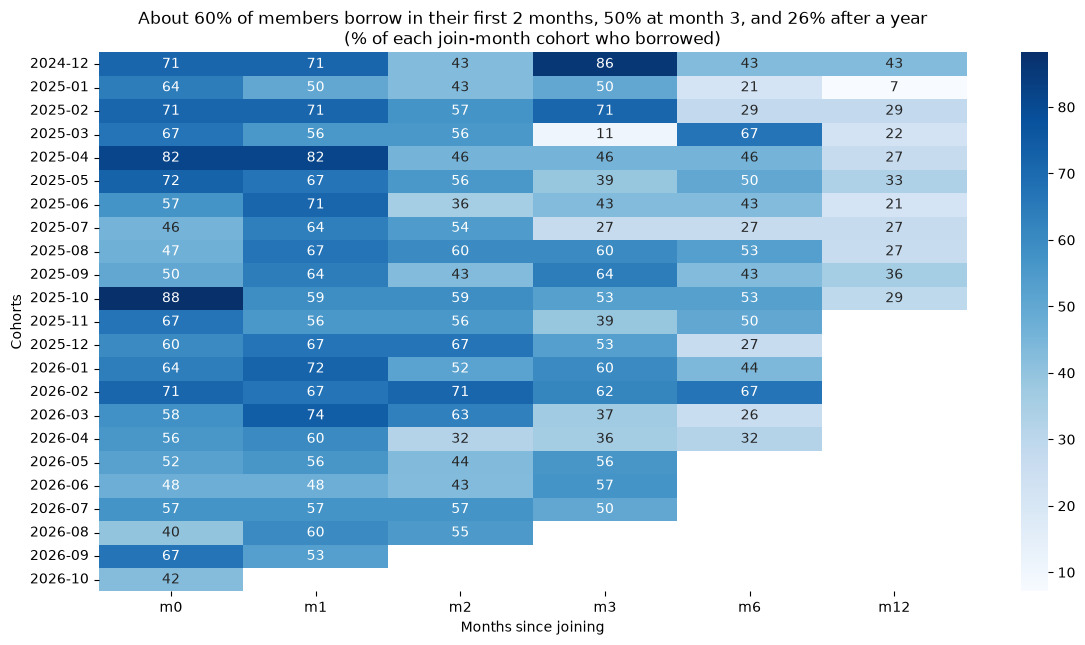

In [27]:
plt.figure(figsize=(14, 7))
sns.heatmap(data=cohort, annot=True, fmt=".0f", cmap="Blues")
plt.title("About 60% of members borrow in their first 2 months, 50% at month 3, and 26% after a year\n(% of each join-month cohort who borrowed)")
plt.xlabel("Months since joining")
plt.ylabel("Cohorts")
plt.savefig("images/cohort_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


## Key insights

1. **Many reservations are cancelled.** 22% of online reservations (47 of 213) are cancelled before the book is ready. That's the biggest drop in the reservation funnel, bigger than members not picking up their books (18%). The library should find out why reservations are cancelled (e.g. waiting time) and buy extra copies of the books with the longest queues.

2. **Strong growth, but a summer dip.** Monthly loans grew 8× (33 in Jan 2025 -> 267 in Oct 2026), but fell 28% in summer 2026 (241 in May -> 173 in June), likely because students are on holiday. The library should run a summer reading challenge for students to keep them borrowing.

3. **A small group drives most loans.** The top 25% of members make 69.3% of all loans, so the library depends on a few heavy readers: if some of them leave, loans drop a lot. The library should keep them (e.g. premium benefits) and remind the less active 75% about their membership by email.

4. **New members start borrowing later.** 35 of 400 members (9%) never borrowed, and the share of new members who borrow in their first month fell from 69% to 56% for the 2026 cohorts. The library should send a welcome message in the first 14 days, and could add a loyalty card with a small prize for the 10th loan.

5. **Popular books have too few copies.** Demand per copy matters more than total loans: *Sapiens* has 165 loans on 6 copies (27.5 per copy), more than *O'tkan kunlar* with 228 loans on 10 copies (22.8 per copy). The library should buy copies based on loans per copy, not total loans.